<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Robustness of the density classification to the radius / ambient floor / probability threshold.
> - **Manuscript panels:** Supplementary (density hyperparameters)
> - **Inputs:** Runs of `3_density_hyperparameter.py`
> - **Outputs:** Stability plots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

We analyze the results from hyperparameter tuning for density 

# Import package

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, get_cmap
from sklearn.metrics.pairwise import cosine_similarity


Total transcripts tracked: 23790756
Variable transcripts analyzed (excluding pure Intracellular): 8350561


/tmp/ipykernel_3249509/1823622187.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  'radius': get_cmap("Purples"),
/tmp/ipykernel_3249509/1823622187.py:77: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  'ambient_floor': get_cmap("Oranges"),
/tmp/ipykernel_3249509/1823622187.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  'prob_density': get_cmap("Blues")


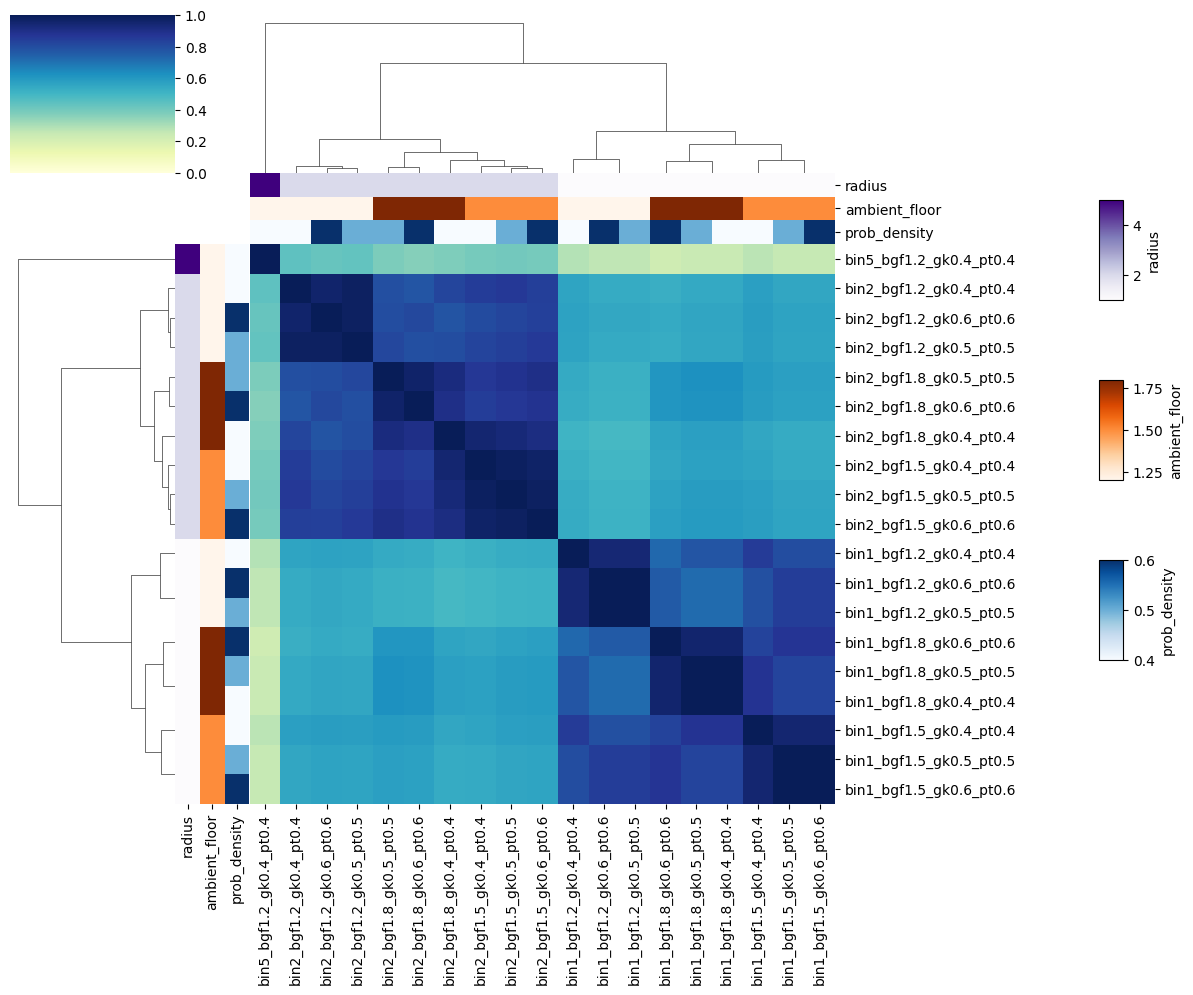


Lowest Adjusted Rand Index (Max Divergence): 0.2262
Configuration 1: bin5_bgf1.2_gk0.4_pt0.4
Configuration 2: bin1_bgf1.8_gk0.6_pt0.6


In [4]:
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, get_cmap
from sklearn.metrics import adjusted_rand_score

# --- Configuration Path ---
base_figures_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k_param_density"

# --- Step 1: Collect Data Columns ---
summary_list = []
class_metadata_list = []

for param_suffix in os.listdir(base_figures_dir):
    folder_path = os.path.join(base_figures_dir, param_suffix, param_suffix)
    summary_path = os.path.join(folder_path, "pipeline_summary.csv")
    xrna_metadata_path = os.path.join(folder_path, "pipeline_xrna_metadata.csv")
    
    if os.path.isfile(summary_path) and os.path.isfile(xrna_metadata_path):
        # Read and annotate summary statistics
        summary_df = pd.read_csv(summary_path)
        summary_df["param_set"] = param_suffix
        summary_list.append(summary_df)
        
        # Read raw transcript classifications column
        class_df = pd.read_csv(xrna_metadata_path)
        proportion = class_df[['extracellular_proportion']]
        proportion.columns = [param_suffix]
        class_metadata_list.append(proportion)

# Combine into matching structural dataframes
combined_summary = pd.concat(summary_list, ignore_index=True)
combined_classes = pd.concat(class_metadata_list, axis=1)

# Filter missing or uncompleted transcript indices 
combined_classes = combined_classes[np.sum(combined_classes.isna(), axis=1) == 0]

# --- Step 2: Drop Constant Intracellular Transcripts ---
# Intracellular was encoded as 3. We exclude rows where every single run 
# classified the transcript as Intracellular to evaluate only extracellular shifting.
is_always_intracellular = (combined_classes == 3).all(axis=1)
filtered_classes = combined_classes[~is_always_intracellular]

print(f"Total transcripts tracked: {len(combined_classes)}")
print(f"Variable transcripts analyzed (excluding pure Intracellular): {len(filtered_classes)}")

# --- Step 3: Compute Pairwise Adjusted Rand Index (ARI) ---
run_names = filtered_classes.columns
n_runs = len(run_names)
ari_matrix = np.zeros((n_runs, n_runs))

# Compute pairwise ARI elements (immune to integer scale mapping anomalies)
for i in range(n_runs):
    for j in range(n_runs):
        ari_matrix[i, j] = adjusted_rand_score(filtered_classes.iloc[:, i], filtered_classes.iloc[:, j])

ari_df = pd.DataFrame(ari_matrix, index=run_names, columns=run_names)

# --- Step 4: Parameter Slicing & Parsing (New Nomenclature) ---
def parse_params(name):
    parts = name.split('_')
    return pd.Series({
        'radius': int(parts[0][3:]),             # Maps the legacy 'bin' to radius
        'ambient_floor': float(parts[1][3:]),    # Maps the legacy 'bgf' to ambient_floor
        'prob_density': float(parts[3][2:])      # Maps the legacy 'pt' to prob_density
    })

metadata = ari_df.index.to_series().apply(parse_params)

# --- Step 5: Define Downstream Color Mappings (New Nomenclature) ---
param_cmaps = {
    'radius': get_cmap("Purples"),
    'ambient_floor': get_cmap("Oranges"),
    'prob_density': get_cmap("Blues")
}

param_norms = {
    key: Normalize(vmin=metadata[key].min(), vmax=metadata[key].max())
    for key in metadata.columns
}

row_colors = pd.DataFrame({
    key: metadata[key].apply(lambda x: param_cmaps[key](param_norms[key](x)))
    for key in metadata.columns
}, index=metadata.index)

# --- Step 6: Generate and Save Heatmap ---
g = sns.clustermap(
    ari_df,
    cmap="YlGnBu", 
    vmin=0.0, vmax=1.0,  # ARI is strictly bounded between 0 (random) and 1 (identical)
    figsize=(12, 10),
    row_colors=row_colors,
    col_colors=row_colors
)

# Append revised dynamic legends to plot axes
for i, key in enumerate(metadata.columns):
    cbar_ax = g.fig.add_axes([0.92, 0.7 - i * 0.18, 0.02, 0.1])
    sm = ScalarMappable(norm=param_norms[key], cmap=param_cmaps[key])
    sm.set_array([])
    g.fig.colorbar(sm, cax=cbar_ax, orientation="vertical", label=key)

plt.subplots_adjust(right=0.7)

plt.savefig(os.path.join(base_figures_dir, 'ari_similarity_by_run_density_classes.pdf'))
plt.show()

# --- Step 7: Maximum Divergence Extraction ---
ari_no_diag = ari_df.copy()
np.fill_diagonal(ari_no_diag.values, np.nan)

min_val = ari_no_diag.min().min()
min_idx = ari_no_diag.stack().idxmin()

print("\n" + "="*60)
print(f"Lowest Adjusted Rand Index (Max Divergence): {min_val:.4f}")
print(f"Configuration 1: {min_idx[0]}")
print(f"Configuration 2: {min_idx[1]}")
print("="*60)

##  Batch running of the pipeline

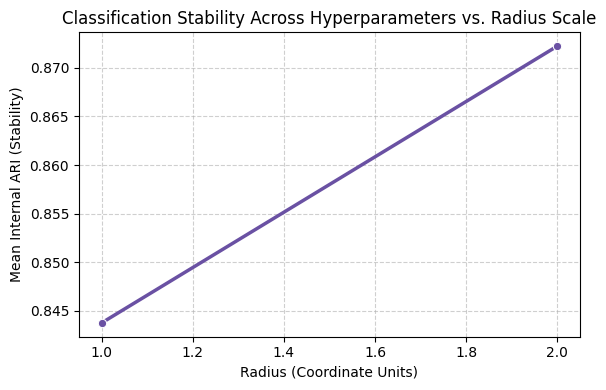

In [17]:
# Compute internal similarity within each radius group
radius_stability = []
unique_radii = metadata['radius'].unique()

for r in unique_radii:
    # Find all runs that used this specific radius
    runs_with_radius = metadata[metadata['radius'] == r].index
    if len(runs_with_radius) > 1:
        # Extract the sub-matrix of comparisons within this radius tier
        sub_matrix = ari_df.loc[runs_with_radius, runs_with_radius].copy()
        # Exclude self-comparisons (diagonal elements)
        np.fill_diagonal(sub_matrix.values, np.nan)
        mean_ari = sub_matrix.mean().mean()
        radius_stability.append({'radius': r, 'internal_stability_ari': mean_ari})

stability_df = pd.DataFrame(radius_stability)

# --- Plot 1: Internal Stability across Radii ---
plt.figure(figsize=(6, 4))
sns.lineplot(data=stability_df, x='radius', y='internal_stability_ari', marker='o', linewidth=2.5, color='#6a51a3')
plt.title('Classification Stability Across Hyperparameters vs. Radius Scale')
plt.xlabel('Radius (Coordinate Units)')
plt.ylabel('Mean Internal ARI (Stability)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(base_figures_dir, 'radius_internal_stability.pdf'))
plt.show()

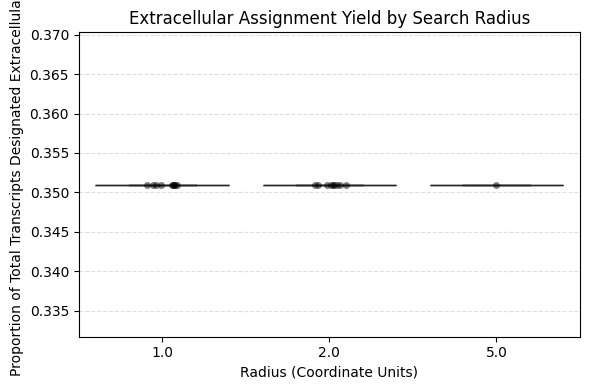

In [18]:
# Extract parameters from the summary param_set column to align with the new nomenclature
summary_metadata = combined_summary['param_set'].apply(parse_params)
combined_summary['radius'] = summary_metadata['radius']

# --- Plot 2: Extracellular Proportions by Radius ---
plt.figure(figsize=(6, 4))
sns.boxplot(data=combined_summary, x='radius', y='proportion_of_extracellular', palette='Purples', hue='radius', legend=False)
sns.stripplot(data=combined_summary, x='radius', y='proportion_of_extracellular', color='black', alpha=0.5, jitter=0.1)
plt.title('Extracellular Assignment Yield by Search Radius')
plt.xlabel('Radius (Coordinate Units)')
plt.ylabel('Proportion of Total Transcripts Designated Extracellular')
plt.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(base_figures_dir, 'radius_vs_extracellular_proportion.pdf'))
plt.show()

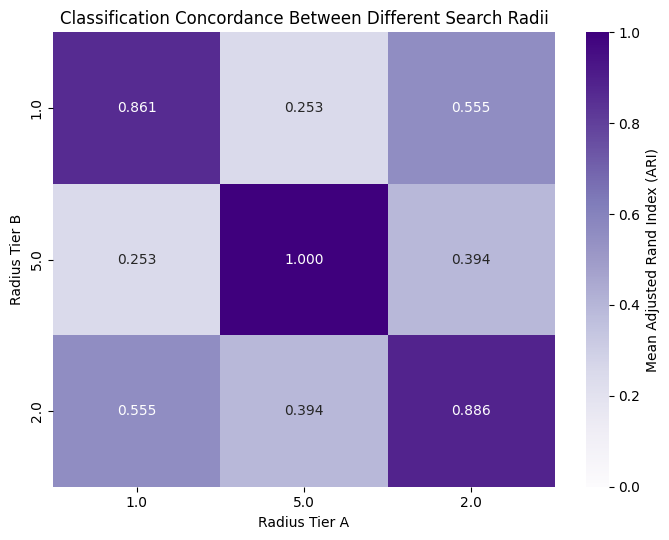

In [19]:
# Group the massive ARI matrix by the parsed radius values
cross_radius_ari = pd.DataFrame(index=unique_radii, columns=unique_radii, dtype=float)

for r1 in unique_radii:
    for r2 in unique_radii:
        runs_r1 = metadata[metadata['radius'] == r1].index
        runs_r2 = metadata[metadata['radius'] == r2].index
        # Mean ARI of all pairwise comparisons between runs of radius 1 and radius 2
        mean_cross_ari = ari_df.loc[runs_r1, runs_r2].values.mean()
        cross_radius_ari.loc[r1, r2] = mean_cross_ari

# --- Plot 3: Aggregated Cross-Radius ARI Matrix ---
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cross_radius_ari.astype(float), 
    annot=True, 
    fmt=".3f", 
    cmap="Purples", 
    vmin=0.0, vmax=1.0,
    cbar_kws={'label': 'Mean Adjusted Rand Index (ARI)'}
)
plt.title('Classification Concordance Between Different Search Radii')
plt.xlabel('Radius Tier A')
plt.ylabel('Radius Tier B')
plt.tight_layout()
plt.savefig(os.path.join(base_figures_dir, 'cross_radius_stability_heatmap.pdf'))
plt.show()